# Trial1: climbing analysis and personalized-motion report

Read Sections 1–10 for the current workflow and results. Historical experiments remain in Appendix A with their original bodies, scenes and frame intervals. All technical quantities below come from saved results unless an explicit generation switch is enabled.

**Reading convention:** source-person observations → target-body motion → Anny appearance transfer. These outputs answer different questions. The saved full trajectory is diagnostic and has not passed physical validation.

1. [Overview and key findings](#section-1)
2. [Inputs and scene assumptions](#section-2)
3. [Pose tracking and data quality](#section-3)
4. [Holds and route](#section-4)
5. [Contacts and movement timing](#section-5)
6. [Personalized body and constraints](#section-6)
7. [Full-sequence results and diagnostics](#section-7)
8. [Short-clip candidate comparison](#section-8)
9. [Anny visualization of the selected full sequence](#section-9)
10. [Conclusions and reproducibility](#section-10)

[Appendix A — historical experiments](#appendix-a) · [Appendix B — detailed checks](#appendix-b) · [Appendix C — artifact index](#appendix-c)


<a id="section-1"></a>
## 1. Overview and key findings

Use **Python (Beta Translator)**. The defaults read saved evidence and reports; fitting, rendering and avatar generation are disabled. The overview indexes the saved runs; Section 7 establishes `FULL_RESULT`, the exact source used by Section 9. Section 8 uses a separate `COMPARISON_RESULT` and never replaces it.

Change display switches to inspect review tools, additional tables or historical media. Editing a user profile requires a matching saved trajectory or an explicitly requested new fit. Review exports are drafts until separately adopted as pipeline inputs.


In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown
from beta_translator.body_model import BodyModel
from beta_translator.trials import load_config
from beta_translator import body_notebook as view
from notebooks import trial_workflow as wf
from notebooks import report_workflow as report

ROOT = view.project_root()
TRIAL = 'trial1'
USER_PROFILE = ROOT / 'configs/users/trial_user_175.json'
FULL_SOURCE_RUN = None  # Optional repository-relative path to an existing full shared-body run.
RUN_FULL_SEQUENCE = False
RUN_COMPARISON = False
RUN_AVATAR = False
RENDER_COMPARISON = False
ITERATIONS = 150  # Budget for explicitly requested new fits; saved runs retain their own budgets.
SHOW_REVIEW_TOOLS = False
SHOW_COMPARISON_VIDEO = False
SHOW_DETAILS = False
SHOW_HISTORY = False

model = BodyModel(user_profile=USER_PROFILE)
HEIGHT_CM = model.height_cm
config = load_config(ROOT, TRIAL)
CATALOG = report.read_json(ROOT / 'notebooks/workflow_catalog.json')
EVIDENCE = wf.Evidence(ROOT, config)
SAVED_FULL = report.saved_full(ROOT, config, source_run=FULL_SOURCE_RUN)
SAVED_COMPARISON = report.saved_comparison(ROOT, config)
display(pd.DataFrame([
    report.result_identity(SAVED_FULL, 'Saved full-sequence diagnostic'),
    report.result_identity(SAVED_COMPARISON, 'Separate saved short-clip comparison'),
]))
display(Markdown('These are separate saved experiments. The frame intervals, iteration budgets and candidate sets above '
                 'belong to their recorded runs. Their failure totals are not a like-for-like ranking.'))


,Role,Frames,Seconds,Height / span (cm),Iteration budget,Active candidates
0,Saved full-sequence diagnostic,0–416,13.9,175 / 176.0,15,steady
1,Separate saved short-clip comparison,113–136,0.8,175 / 176.0,35,steady


These are separate saved experiments. The frame intervals, iteration budgets and candidate sets above belong to their recorded runs. Their failure totals are not a like-for-like ranking.

<a id="section-2"></a>
## 2. Inputs and scene assumptions

Trial1 uses a projected image-plane model with a 25 cm depth prior and conditional ground evidence. The 46 cm reference-image measurement supplies the existing scale. Neither a complete 3D camera nor a metric floor was measured.

The source video is an observation of the filmed climber. The demonstration target profile is a separate person. Scene fields below belong to the selected saved full run; they are not inferred from the target height.


In [3]:
wf.video(ROOT, EVIDENCE.video, width=500)
saved_settings = SAVED_FULL['provenance']['config']['trial_config']
display(pd.DataFrame([{'Trial': TRIAL, 'Frames': config['frame_count'], 'FPS': config['fps'],
                       'Reference frame': EVIDENCE.reference, 'Scene adapter': saved_settings['adapter']}]))
display(pd.DataFrame([saved_settings['scene']]))
report.artifact_links(ROOT, [Path(SAVED_FULL['output_dir']) / 'scene.json', ROOT / 'configs/trials' / f'{TRIAL}.json'],
                      ['Saved scene and assumptions', 'Trial input configuration'])


[trial1.mp4](videos/trial1.mp4)

,Trial,Frames,FPS,Reference frame,Scene adapter
0,trial1,417,30.0,0,projected_ground


,depth_cm
0,25.0


[Saved scene and assumptions](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/scene.json) · [Trial input configuration](configs/trials/trial1.json)

### Calibration evidence

Trial1 uses the existing 46 cm reference-image measurement (about 1.798 px/cm). Image-up is assumed to oppose gravity; perspective, depth and floor geometry are not recovered. The selected target height does not determine wall scale.


In [4]:
from beta_translator.trial1_sequence import TRIAL1_SCALE
print('Saved Trial1 scale:', TRIAL1_SCALE, 'px/cm')
wf.link(ROOT, ROOT / 'data/H44_H28_confirmed_reference.json')


Saved Trial1 scale: 1.7980508245001927 px/cm


[H44_H28_confirmed_reference.json](data/H44_H28_confirmed_reference.json)

<a id="section-3"></a>
## 3. Pose tracking and data quality

The saved skeleton and confidence values describe source observations. Low-visibility and identity-rejected samples remain missing; display interpolation is not contact evidence. The reference frame below overlays the observed skeleton and route. Enable `SHOW_REVIEW_TOOLS` for the interactive frame viewer.


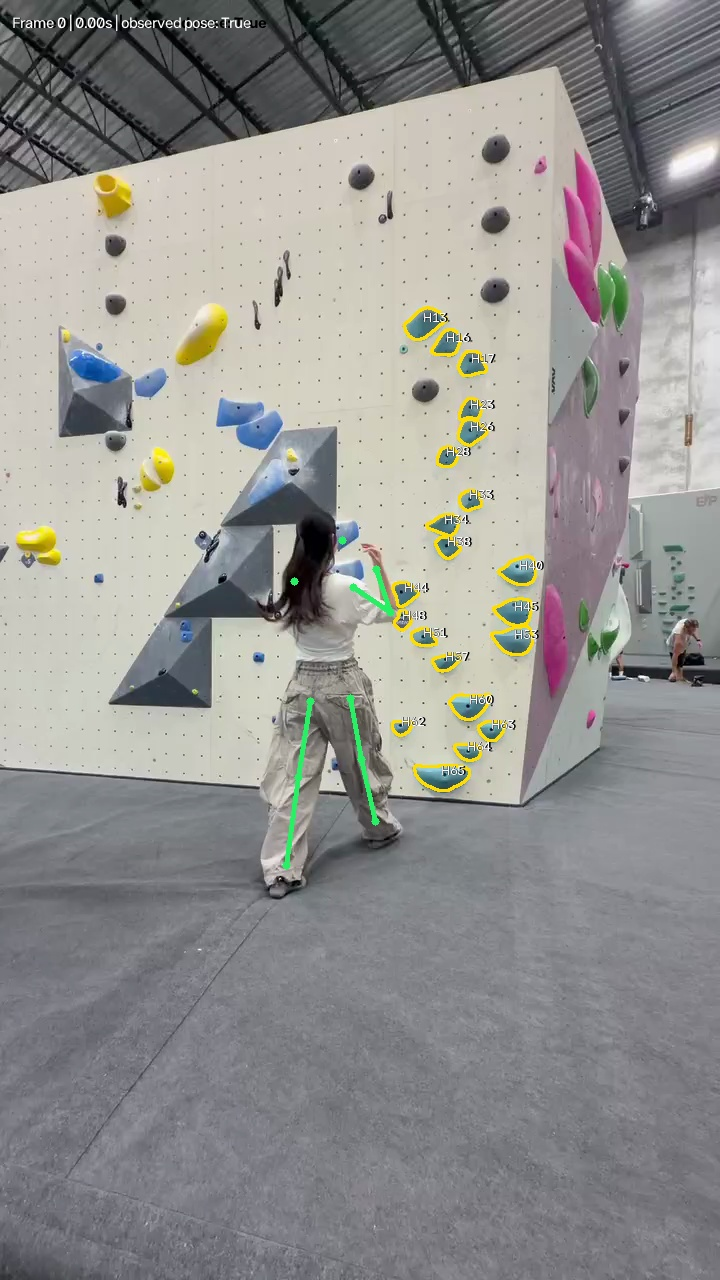

[Observed skeleton video](outputs/videos/pose_output_h264.mp4)

In [5]:
EVIDENCE.show_image(frame=EVIDENCE.reference, skeleton=True)
if SHOW_REVIEW_TOOLS:
    source_viewer = wf.frame_viewer(EVIDENCE, initial=EVIDENCE.reference)
pose_video = EVIDENCE.root / 'videos/pose_output_h264.mp4'
if pose_video.exists():
    report.artifact_links(ROOT, [pose_video], ['Observed skeleton video'])
if TRIAL == 'trial2':
    report.artifact_links(ROOT, [ROOT / 'outputs/trial2/videos/identity_comparison_h264.mp4'],
                          ['Historical identity-tracking comparison'])


<a id="section-4"></a>
## 4. Holds and route

Candidate masks and route membership are separate. Reconstruction combines observed wall pixels; it does not recover a complete metric 3D scene. The preview shows all candidates; the saved route remains the input to cached predictions.

Enable `SHOW_REVIEW_TOOLS` to change the in-memory route and export a new review. That export does not update predictions, `FULL_RESULT` or the Anny videos.


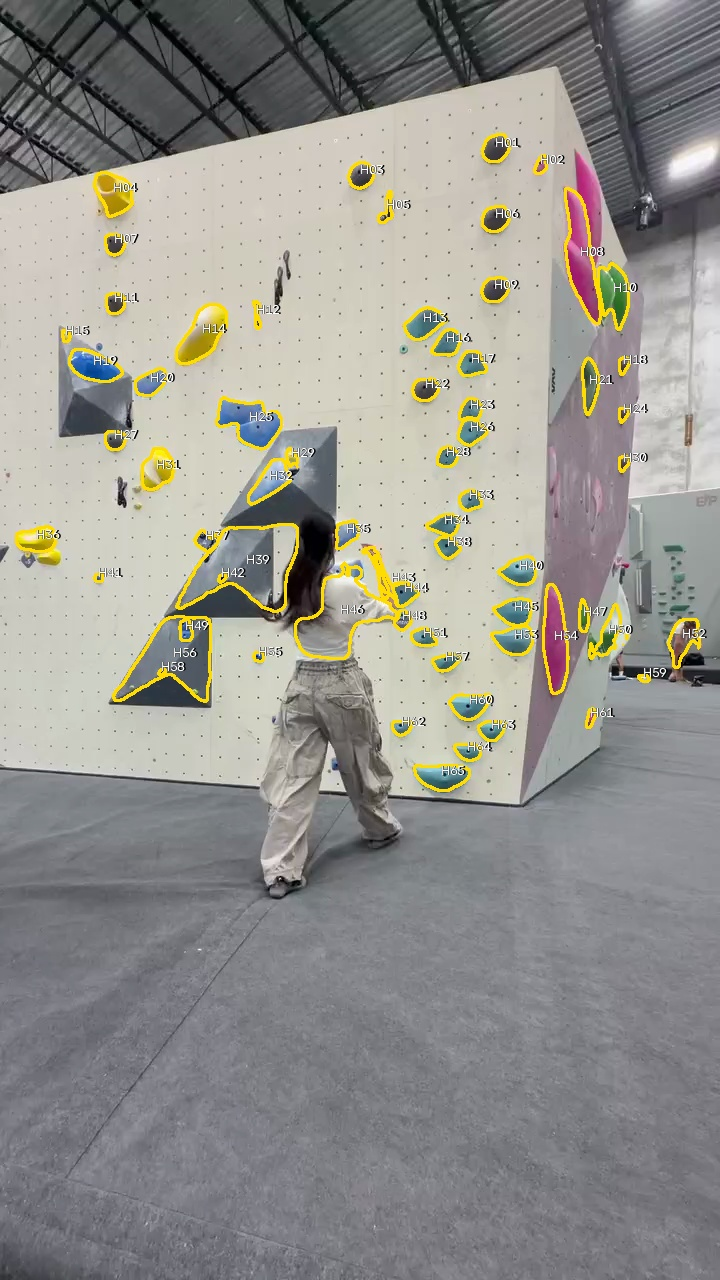

,Candidate holds,Saved route holds,Saved route IDs
0,65,21,"H65, H64, H63, H60, H57, H51, H53, H45, H40, H..."


[Saved hold map](outputs/state/reviewed_hold_map.npz) · [Saved alignment](outputs/state/alignment_cache.npz)

In [6]:
EVIDENCE.show_image(ids=list(EVIDENCE.masks))
display(pd.DataFrame([{'Candidate holds': len(EVIDENCE.records), 'Saved route holds': len(EVIDENCE.saved_selected),
                       'Saved route IDs': ', '.join(EVIDENCE.saved_selected)}]))
if SHOW_DETAILS:
    hold_table = pd.DataFrame(EVIDENCE.records)
    display(hold_table[[c for c in ['hold_id', 'score', 'cx_px', 'cy_px', 'source', 'review_status'] if c in hold_table]])
    display(pd.Series({s: sum(v[1] == s for v in EVIDENCE.transforms.values())
                       for s in sorted({v[1] for v in EVIDENCE.transforms.values()})}, name='Alignment status'))
if SHOW_REVIEW_TOOLS:
    route_controls = wf.route_picker(EVIDENCE)
report.artifact_links(ROOT, [EVIDENCE.map_path, EVIDENCE.alignment_path], ['Saved hold map', 'Saved alignment'])


<a id="section-5"></a>
## 5. Contacts and movement timing

The Way Up-based temporal model proposes hold/free/unresolved contact states and release/arrival times. Confidence coverage is not accuracy. Release is the first frame leaving the old contact; arrival is the first new-contact frame.

The video replays **the source person and decoded contacts**, not a retargeted body. The table and replay use the saved input bundle. Optional BEFORE/AFTER review exports a separate file; unconfirmed timing remains a draft. No review button silently changes the saved motion shown later.


In [7]:
move_columns = ['moving_limb', 'from_hold', 'to_hold', 'before_frame', 'release_frame', 'arrival_frame', 'after_frame']
display(pd.DataFrame(EVIDENCE.prediction['moves']).reindex(columns=move_columns))
replay = EVIDENCE.root / 'videos/automatic_contacts_h264.mp4'
if not replay.exists():
    replay = EVIDENCE.root / 'videos/wall_motion_h264.mp4'
wf.video(ROOT, replay, width=650)
if SHOW_DETAILS:
    display(pd.crosstab(EVIDENCE.contacts.limb, EVIDENCE.contacts.hold_id))
if SHOW_REVIEW_TOOLS:
    contact_review = wf.ContactReview(EVIDENCE, HEIGHT_CM)
    display(contact_review.ui)
display(Markdown('**Input adoption:** saved canonical evidence is active. New route/contact exports are separate review artifacts. '
                 'Use a deliberately updated input configuration and new fit to evaluate revised evidence.'))
report.artifact_links(ROOT, [EVIDENCE.root / 'automatic/predictions/automatic_contacts.json',
                            EVIDENCE.root / 'automatic/predictions/limb_contacts.csv'],
                      ['Saved movement proposals', 'Saved limb-frame contacts'])


,moving_limb,from_hold,to_hold,before_frame,release_frame,arrival_frame,after_frame
0,left_hand,H44,H28,105,113,136,143
1,left_hand,H28,H26,233,241,241,248
2,left_hand,H26,H16,280,288,305,312
3,right_hand,H44,H33,68,76,103,110
4,right_hand,H33,H26,203,211,226,233
5,right_hand,H26,H23,275,283,283,290
6,right_hand,H23,H17,300,308,327,334
7,left_foot,H62,H51,172,180,206,213
8,right_foot,H65,H60,145,153,173,180
9,right_foot,H60,H45,258,266,286,293


[wall_motion_h264.mp4](outputs/videos/wall_motion_h264.mp4)

**Input adoption:** saved canonical evidence is active. New route/contact exports are separate review artifacts. Use a deliberately updated input configuration and new fit to evaluate revised evidence.

[Saved movement proposals](outputs/automatic/predictions/automatic_contacts.json) · [Saved limb-frame contacts](outputs/automatic/predictions/limb_contacts.csv)

<a id="section-6"></a>
## 6. Personalized body and constraints

All three trials use `BodyModel`: 32 pose coordinates, fixed user dimensions, anatomical arms and legs, and common contact definitions. **176 cm is bilateral fingertip-to-fingertip arm span.** The default 70 kg mass, proportions, capacity and fatigue parameters are project assumptions.

Shoulder envelopes, capsule self-collision, joint-moment capacity, causal fatigue and inertial balance participate in the same optimization and audit. They are simplified soft mechanisms with uncalibrated parameters. Hard coordinate/rate bounds, missing model coverage and physical validation are separate concepts. Detailed constraint tables and source-chain checks are available in Appendix B.


In [8]:
from beta_translator.body_user import profile_table
display(pd.DataFrame(profile_table(model.user_profile)))
constraint_inventory = pd.DataFrame(model.constraints)
display(constraint_inventory.groupby('enforcement', sort=False).size().rename('Declared mechanisms').to_frame())
report.artifact_links(ROOT, [USER_PROFILE, ROOT / 'docs/personalized_body.md', ROOT / 'docs/body_constraint_specification.md'],
                      ['Requested user profile', 'Active personalized model', 'Constraint specification and historical context'])


,parameter,value,unit
0,height,175.0,cm
1,arm_span,176.0,cm
2,mass,70.0,kg
3,upper_arm,30.0,cm
4,forearm,24.0,cm
5,thigh,43.0,cm
6,shank,42.0,cm
7,shoulder_w,40.0,cm
8,hip_w,30.0,cm
9,torso,49.0,cm


,Declared mechanisms
enforcement,
hard,7
partial,5
profile_soft_and_audit,6
not_implemented,11
parameterized_audit,2
soft_and_audit,3
audit,3
gate,1


[Requested user profile](configs/users/trial_user_175.json) · [Active personalized model](docs/personalized_body.md) · [Constraint specification and historical context](docs/body_constraint_specification.md)

<a id="section-7"></a>
## 7. Full-sequence results and diagnostics

This section selects **one complete native-frame run** as `FULL_RESULT`. By default it loads the source of the saved full Anny result, then checks the trial, scene, profile and frame range. The numerical audit and Section 9 therefore describe the same trajectory.

`RUN_FULL_SEQUENCE=True` explicitly requests a new fit using the current profile and `ITERATIONS`; rendering is disabled in that call. It replaces `FULL_RESULT` for this notebook session. A new run is not evidence of convergence, and an existing Anny video will be used only if its source hashes match.


In [9]:
if RUN_FULL_SEQUENCE:
    FULL_RESULT = model.fit(TRIAL, project=ROOT, frames='all', iterations=ITERATIONS, render=False)
else:
    FULL_RESULT = report.saved_full(ROOT, config, model.user_profile, source_run=FULL_SOURCE_RUN)
report.validate_motion(FULL_RESULT, config, model.user_profile, full=True)
FULL_OUT = Path(FULL_RESULT['output_dir'])
report.show_motion(ROOT, FULL_RESULT, details_enabled=SHOW_DETAILS)


,Role,Frames,Seconds,Height / span (cm),Iteration budget,Active candidates
0,Full-sequence diagnostic,0–416,13.9,175 / 176.0,15,steady


**Status:** `diagnostic_only_not_feasible`. **Solver converged:** False. **Frames with at least one ranked failure:** 417/417. **Physical validation:** False.

,Check,Failed frames,Total frames
0,Contact,400,417
1,Support,417,417
2,Shoulder envelope,334,417
3,Self-collision,166,417
4,Joint-moment capacity,415,417
5,Fatigue,417,417
6,Dynamic balance,46,417
7,Departing contact load,14,417


This saved full run tested one active candidate (`steady`); it does not establish a winner over untested full-sequence alternatives.

Counts overlap and must not be added. Contact/support checks use assumed geometry and capacity. See the matching full-sequence videos in Section 9.

[Run and provenance](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/summary.json) · [Candidate metrics](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/candidate_comparison.csv) · [Complete constraint audit](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/steady/constraints.csv)

<a id="section-8"></a>
## 8. Short-clip candidate comparison

This is a **separate short-clip comparison**, not the full trajectory above. The recorded anatomical control and active candidate share the same short interval and user geometry. Their results must not be compared directly with full-run failure totals or used to splice a route.

The default shows compact metrics and links. `SHOW_COMPARISON_VIDEO=True` plays its saved comparison. `RUN_COMPARISON=True` explicitly fits the verification interval; `RENDER_COMPARISON=True` explicitly creates its figures/video if needed. None of these changes `FULL_RESULT`.


In [10]:
COMPARISON_RESULT = None
if RUN_COMPARISON:
    COMPARISON_RESULT = model.fit(TRIAL, project=ROOT, frames='verification', iterations=ITERATIONS, render=False)
elif SAVED_COMPARISON['provenance']['config'].get('user_profile') == model.user_profile:
    COMPARISON_RESULT = report.saved_comparison(ROOT, config, model.user_profile)
else:
    display(Markdown('No indexed short comparison matches the requested profile. The full result remains selected. '
                     'Set RUN_COMPARISON=True only when you intend to fit this separate interval.'))
if COMPARISON_RESULT is not None:
    report.validate_motion(COMPARISON_RESULT, config, model.user_profile)
    report.show_comparison(ROOT, COMPARISON_RESULT, show_video=SHOW_COMPARISON_VIDEO,
                           render=RENDER_COMPARISON, details_enabled=SHOW_DETAILS)


,Role,Frames,Seconds,Height / span (cm),Iteration budget,Active candidates
0,Short-clip comparison only,113–136,0.8,175 / 176.0,35,steady


,candidate,eligible_for_selection,converged,total_failed_frames,max_contact_gap_cm,selection_status
0,steady,True,False,24,0.757293,diagnostic_only_not_feasible
1,anatomical_control,False,False,24,0.140150,comparison_only


The anatomical control shares this clip and user profile, but uses earlier objectives and cannot win selection. This comparison does not rank full-sequence alternatives. Failures remain visible for all candidates.

[Short-clip comparison video](outputs/trial1/shared_body/target_175cm_0113_0136_b552020f1f38/presentation_6c9d97e88b/candidate_comparison_3d.mp4) · [Short-clip selected video](outputs/trial1/shared_body/target_175cm_0113_0136_b552020f1f38/presentation_6c9d97e88b/selected_plan_3d.mp4) · [Short-clip metrics](outputs/trial1/shared_body/target_175cm_0113_0136_b552020f1f38/presentation_6c9d97e88b/metrics.png)

[Short-clip run and provenance](outputs/trial1/shared_body/target_175cm_0113_0136_b552020f1f38/summary.json)

<a id="section-9"></a>
## 9. Anny visualization of the selected full sequence

Both full-sequence videos below must come from **`FULL_RESULT` in Section 7**. The adapter is checked against its source summary, selected trajectory, metrics, profile, candidate and frame range. A matching saved avatar is loaded without regeneration. If none exists, the notebook reports that absence instead of showing another run.

`RUN_AVATAR=True` explicitly maps `FULL_OUT` to Anny; it does not refit motion. Mapping drift measures mesh-to-solver agreement. Mesh-to-hold gap and wall penetration measure different issues. Fingers retain a template pose; the overlay retains the original climber and has no resolved person/wall occlusion. Appearance transfer does not resolve source failures.


In [11]:
report.validate_motion(FULL_RESULT, config, model.user_profile, full=True)
if RUN_AVATAR:
    from beta_translator.avatar_pipeline import run_avatar
    avatar_result = run_avatar(ROOT, Path(FULL_RESULT['output_dir']))
    AVATAR_OUT = Path(avatar_result['output_dir'])
else:
    AVATAR_OUT = report.matching_avatar(ROOT, FULL_RESULT)
if AVATAR_OUT is None:
    display(Markdown('No saved Anny result matches FULL_RESULT. No alternate video is substituted. '
                     'Set RUN_AVATAR=True only when you intend to generate the matching appearance transfer.'))
else:
    report.show_avatar(ROOT, FULL_RESULT, AVATAR_OUT)


**Exact source match:** `target_175cm_0000_0416_86258d08517d` / `steady`. Frames 0–416 at 30 FPS. **Mesh-to-solver mapping passed:** True. **Physical validation:** False.

,Measure,Value
0,Maximum mesh-to-solver mapping drift (cm),0.041193
1,Frames with mesh-to-hold gap > 0.1 cm,400.000000
2,Frames with source constraint failure,417.000000
3,Maximum assumed-wall penetration (cm),22.367761


[avatar_comparison_3d.mp4](outputs/trial1/avatars/anny_175cm_0000_0416_d15d2578a4fd/avatar_comparison_3d.mp4)

[avatar_source_overlay.mp4](outputs/trial1/avatars/anny_175cm_0000_0416_d15d2578a4fd/avatar_source_overlay.mp4)

[Avatar provenance and checks](outputs/trial1/avatars/anny_175cm_0000_0416_d15d2578a4fd/summary.json) · [Per-frame surface audit](outputs/trial1/avatars/anny_175cm_0000_0416_d15d2578a4fd/surface_metrics.csv)

<a id="section-10"></a>
## 10. Conclusions and reproducibility

The current workflow connects reviewed video evidence, a shared personalized model and a provenance-matched human surface. Its saved full trajectory is a diagnostic result. **Numerical convergence, modeled feasibility and real-human validity are different claims; physical validation remains false.**

Review conditional ground intervals, support changes and the projected wall/depth assumptions before changing optimization budgets. Muscle paths, measured grip capacity, coupled personal ROM, reliable shoe/contact orientation, continuous collision, impacts and forward replay remain incomplete or unvalidated.

For reproduction, keep the saved run, source evidence and manifests together. Historical failure counts use different models and bodies. Read Appendix A for method evolution, Appendix B for detailed checks, and Appendix C for the full artifact index.


In [12]:
display(pd.DataFrame([
    {'Artifact': 'Full motion used by Sections 7 and 9', 'Location': str(FULL_OUT.relative_to(ROOT))},
    {'Artifact': 'Separate short comparison', 'Location': str(Path(COMPARISON_RESULT['output_dir']).relative_to(ROOT)) if COMPARISON_RESULT else 'No matching comparison selected'},
    {'Artifact': 'Matching Anny output', 'Location': str(AVATAR_OUT.relative_to(ROOT)) if AVATAR_OUT else 'Not generated for this full run'},
]))
report.artifact_links(ROOT, [ROOT / 'docs/complete_trial_notebooks.md', ROOT / 'docs/anny_avatar.md',
                            ROOT / 'docs/automatic_contacts.md'],
                      ['Notebook controls and result flow', 'Anny implementation and limits', 'Contact inference and training'])


,Artifact,Location
0,Full motion used by Sections 7 and 9,outputs/trial1/shared_body/target_175cm_0000_0...
1,Separate short comparison,outputs/trial1/shared_body/target_175cm_0113_0...
2,Matching Anny output,outputs/trial1/avatars/anny_175cm_0000_0416_d1...


[Notebook controls and result flow](docs/complete_trial_notebooks.md) · [Anny implementation and limits](docs/anny_avatar.md) · [Contact inference and training](docs/automatic_contacts.md)

<a id="appendix-a"></a>
## Appendix A. Historical experiments

These experiments explain method development. They keep their recorded bodies, scene hypotheses, intervals and failures. They are not stages rerun by the current full-sequence report. Links are shown by default; set `SHOW_HISTORY=True` to expand saved tables, figures and videos. No historical optimization runs here.


### A.1. Reviewed endpoints and H44 → H28 single-move IK

The original reviewed H44 → H28 demonstration is restored here. Endpoint fits and the continuous single-move video are different products from full-route adaptation. The saved 165 cm target is not the source climber’s measured height. Changing `HEIGHT_CM` does not retarget this historical video.


In [13]:
report.historical_stage(ROOT, CATALOG[TRIAL]['single'], expand=SHOW_HISTORY)


**Recorded scope:** 165 cm; historical manual example. 

[Table 1: ik_endpoints_165cm.json](outputs/state/ik_endpoints_165cm.json)

[Figure 1: ik_endpoints_165cm.png](outputs/images/ik_endpoints_165cm.png)

[Video 1: motion_ik_h264.mp4](outputs/videos/motion_ik_h264.mp4)

[Reference 1: endpoint_annotations.json](outputs/state/endpoint_annotations.json) · [Reference 2: motion_ik_summary.json](outputs/state/motion_ik_summary.json)

### A.2. Gravity IK and full-sequence support optimization

Gravity points downward in the assumed wall coordinate frame. The model estimates COM and allocates contact forces, then checks support reserve and release. It does not identify gravity independently from the video. Both videos preserve every source frame; red marks failures and amber marks uncertainty.


In [14]:
report.historical_stage(ROOT, CATALOG[TRIAL]['support'], expand=SHOW_HISTORY)


**Recorded scope:** 180 cm; all 417 frames; no ground support. 

[Table 1: comparison.csv](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/comparison.csv)

[Video 1: trial1_gravity_180cm_baseline.mp4](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/trial1_gravity_180cm_baseline.mp4) · [Video 2: trial1_support_optimized_180cm_full_sequence.mp4](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/trial1_support_optimized_180cm_full_sequence.mp4)

[Reference 1: review.html](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/review.html) · [Reference 2: frame_diagnostics.csv](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/frame_diagnostics.csv) · [Reference 3: issue_intervals.csv](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/issue_intervals.csv)

[Historical run and provenance](outputs/trial1/support_optimized/target_180cm_b55939aa0a8b/summary.json)

### A.3. Ground evidence and ground-aware adaptation

Ground proposals use image polygons, reviewed intervals and visible heel/toe evidence. They remain conditional, not measured floor geometry. A foot missing a wall hold does not automatically receive ground support. The sole offset and friction are assumptions in this historical 2D model.


In [15]:
report.historical_stage(ROOT, CATALOG[TRIAL]['ground'], expand=SHOW_HISTORY)


**Recorded scope:** 180 cm; all 417 frames; conditional ground support. 

[Table 1: comparison.csv](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/comparison.csv) · [Table 2: ground_evidence.csv](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/ground_evidence.csv)

[Figure 1: ground_evidence.jpg](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/ground_evidence.jpg)

[Video 1: trial1_support_optimized_180cm_full_sequence.mp4](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/trial1_support_optimized_180cm_full_sequence.mp4)

[Reference 1: review.html](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/review.html)

[Historical run and provenance](outputs/trial1/ground_support/target_180cm_bd8c3dc75cd8/summary.json)

### A.4. Full-sequence refinement and convergence review

The refinement checks inner/outer convergence and restores contacts. Singleton-support COM alignment can improve nominal equilibrium while still failing the ±2 cm reserve test. Read convergence, contact gaps, unloading and uncertainty separately; this historical model has different constraints from the current anatomical model.


In [16]:
report.historical_stage(ROOT, CATALOG[TRIAL]['refinement'], expand=SHOW_HISTORY)


**Recorded scope:** 180 cm; all 417 frames; same ground evidence. 

[Table 1: comparison.csv](outputs/trial1/refined_support/target_180cm_f1456408fd1d/comparison.csv) · [Table 2: issue_intervals.csv](outputs/trial1/refined_support/target_180cm_f1456408fd1d/issue_intervals.csv) · [Table 3: release_events.csv](outputs/trial1/refined_support/target_180cm_f1456408fd1d/release_events.csv)

[Figure 1: storyboard.png](outputs/trial1/refined_support/target_180cm_f1456408fd1d/storyboard.png)

[Video 1: trial1_support_optimized_180cm_full_sequence.mp4](outputs/trial1/refined_support/target_180cm_f1456408fd1d/trial1_support_optimized_180cm_full_sequence.mp4)

[Reference 1: review.html](outputs/trial1/refined_support/target_180cm_f1456408fd1d/review.html) · [Reference 2: convergence.json](outputs/trial1/refined_support/target_180cm_f1456408fd1d/convergence.json) · [Reference 3: preunload_checks.csv](outputs/trial1/refined_support/target_180cm_f1456408fd1d/preunload_checks.csv) · [Reference 4: singleton_com_constraints.csv](outputs/trial1/refined_support/target_180cm_f1456408fd1d/singleton_com_constraints.csv)

[Historical run and provenance](outputs/trial1/refined_support/target_180cm_f1456408fd1d/summary.json)

### A.5. Technique candidates, complete-trajectory ranking and selected plan

Candidates test weight shift, leg-drive preference, non-contact flagging and upper-limb load preferences, separately and in combination. These are candidate templates, not confirmed expert technique labels. Every candidate is a complete trajectory; local winners are not stitched. Hand-load proxies do not measure energy or fatigue. The Way Up contact model remains unchanged.


In [17]:
report.historical_stage(ROOT, CATALOG[TRIAL]['techniques'], expand=SHOW_HISTORY)


**Recorded scope:** 180 cm; all 417 native frames. 

[Table 1: candidate_comparison.csv](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/candidate_comparison.csv) · [Table 2: technique_review_queue.csv](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/technique_review_queue.csv)

[Figure 1: source_evidence.jpg](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/source_evidence.jpg)

[Video 1: selected_plan.mp4](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/selected_plan.mp4)

[Reference 1: review.html](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/review.html) · [Reference 2: phase_explanations.csv](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/phase_explanations.csv)

[Historical run and provenance](outputs/trial1/technique_plans/target_180cm_cf107c3b5dfe/summary.json)

### A.6. Previous 175 cm anatomical verification

This preserved comparison predates personalized geometry and active mechanics. It retains its original profile and assumptions; the main report uses the current user file.


In [18]:
old_result = view.saved_result(ROOT, TRIAL, 175.0, index_file='leg_verification_results.json')
old_out = Path(old_result['output_dir'])
report.artifact_links(ROOT, [old_out / 'summary.json', old_out / 'candidate_comparison.csv'],
                      ['Earlier anatomical run', 'Earlier candidate comparison'])
old_presentation = report.saved_presentation(old_result)
if old_presentation is not None:
    report.artifact_links(ROOT, [old_presentation / 'candidate_comparison_3d.mp4'], ['Earlier anatomical comparison video'])
    if SHOW_HISTORY:
        wf.video(ROOT, old_presentation / 'candidate_comparison_3d.mp4')
if SHOW_HISTORY:
    display(pd.read_csv(old_out / 'candidate_comparison.csv'))


[Earlier anatomical run](outputs/trial1/shared_body/target_175cm_0113_0136_1bfaad8728f4/summary.json) · [Earlier candidate comparison](outputs/trial1/shared_body/target_175cm_0113_0136_1bfaad8728f4/candidate_comparison.csv)

[Earlier anatomical comparison video](outputs/trial1/shared_body/target_175cm_0113_0136_1bfaad8728f4/presentation_2079d917c5/candidate_comparison_3d.mp4)

<a id="appendix-b"></a>
## Appendix B. Detailed constraints and anatomical source checks

The full trajectory records its checks and assumptions independently of the short comparison. Links always refer to `FULL_RESULT`. Enable `SHOW_DETAILS` to expand the inventory and rerun the lightweight anatomical transform checks; this does not fit a trajectory.


In [19]:
report.artifact_links(ROOT, [FULL_OUT / 'chain_verification.json', FULL_OUT / 'lower_limb_verification.json',
                            FULL_OUT / 'all_frame_input_validation.json', FULL_OUT / 'constraint_contract.csv'],
                      ['Saved arm-chain verification', 'Saved lower-limb verification',
                       'Native input validation', 'Constraint contract'])
if SHOW_DETAILS:
    display(constraint_inventory[['id', 'enforcement', 'evidence', 'missing']])
    from beta_translator.body_constraints import LEG_NAMES, LEG_LIMITS_DEG
    display(pd.DataFrame(LEG_LIMITS_DEG, index=LEG_NAMES, columns=['Assumed lower bound (degrees)', 'Assumed upper bound (degrees)']))

if SHOW_DETAILS:
    from beta_translator.body_reference import verify_chain
    chain = verify_chain()
    display(pd.Series(chain, name="Source-chain verification"))
    assert chain["rotational_chain_pass"]
    from beta_translator.body_leg_reference import verify_leg_chain
    leg_chain = verify_leg_chain()
    display(pd.Series(leg_chain, name="Lower-limb source verification"))
    assert leg_chain["passed"]


[Saved arm-chain verification](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/chain_verification.json) · [Saved lower-limb verification](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/lower_limb_verification.json) · [Native input validation](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/all_frame_input_validation.json) · [Constraint contract](outputs/trial1/shared_body/target_175cm_0000_0416_86258d08517d/constraint_contract.csv)

<a id="appendix-c"></a>
## Appendix C. Preserved artifacts and reproduction entry points

Source videos, annotations, required prediction caches, active trajectories and notebook snapshots remain available. Two duplicate Trial1 historical runs were archived outside the repository; the catalog uses the retained copies. See the [archive map and cleanup record](docs/history/cleanup_20261105.md) for original paths, provenance differences and restoration instructions. The main `Beta_Translator.ipynb` is unchanged. The old README is preserved as a historical appendix; its former section numbers describe earlier notebook layouts.

The current report is backed by one full motion and an independent short comparison. Extra saved Anny cases below are historical or short-clip displays; selecting one does not change the main full-sequence report. Review exports appear only after a deliberate export action.


In [20]:
archives = sorted((ROOT / 'notebooks/history').glob('*.zip'))
report.artifact_links(ROOT, archives)
report.artifact_links(ROOT, [ROOT / 'docs/history/README_before_report_cleanup_20261105.md',
                            ROOT / 'configs/avatar_results.json', ROOT / 'notebooks/workflow_catalog.json'],
                      ['Historical README and experiment record', 'All saved Anny cases', 'Historical artifact catalog'])
avatar_cases = report.read_json(ROOT / 'configs/avatar_results.json')[TRIAL]
for case, relative in avatar_cases.items():
    report.artifact_links(ROOT, [ROOT / relative / 'summary.json'], [f'{case}: saved Anny provenance'])
if SHOW_HISTORY:
    view.history(ROOT, TRIAL)
print('Review exports:', 'outputs/notebook_reviews/' + TRIAL + '/')


[pre_anatomical_legs_20261105.zip](notebooks/history/pre_anatomical_legs_20261105.zip) · [pre_complete_workflow_20261105.zip](notebooks/history/pre_complete_workflow_20261105.zip) · [pre_personalized_model_20261105.zip](notebooks/history/pre_personalized_model_20261105.zip) · [pre_shared_body_20261104.zip](notebooks/history/pre_shared_body_20261104.zip)

[Historical README and experiment record](docs/history/README_before_report_cleanup_20261105.md) · [All saved Anny cases](configs/avatar_results.json) · [Historical artifact catalog](notebooks/workflow_catalog.json)

[verification: saved Anny provenance](outputs/trial1/avatars/anny_175cm_0113_0136_c482b177e9af/summary.json)

[demonstration: saved Anny provenance](outputs/trial1/avatars/anny_175cm_0103_0180_05340a6289a7/summary.json)

[full: saved Anny provenance](outputs/trial1/avatars/anny_175cm_0000_0416_d15d2578a4fd/summary.json)

Review exports: outputs/notebook_reviews/trial1/
